# 09 · Hybrid Ensemble and Final Comparison

**Goal:** combine XGBoost (hand-made lag features) with the LSTM and the temporal CNN (raw sequences) into a hybrid, and compare all six models on the same hours with MAE, RMSE, R², AQI category accuracy and AQI within-one-category accuracy.

In [1]:
import os
import sys

# Find the project folder (the one that contains config.py) and work from there
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "config.py")):
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

FIG = "reports/figures"
OUT = "data/GeneratedOutput/05.DeepLearning"
os.makedirs(FIG, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [2]:
from backtest import compute_metrics
from hybrid import hybrid_forecast
from aqi import category_accuracy, within_one_category_accuracy

phase1 = pd.read_csv("data/GeneratedOutput/03.ModelTraining/predictions.csv",
                     index_col="forecast_made_at", parse_dates=["forecast_made_at", "forecast_for"])
deep = pd.read_csv(f"{OUT}/predictions.csv", index_col="forecast_made_at", parse_dates=["forecast_made_at"])

predictions = phase1.copy()
predictions["LSTM"] = deep["LSTM"]
predictions["TCN"] = deep["TCN"]
predictions["Hybrid"] = hybrid_forecast(predictions)
predictions.to_csv(f"{OUT}/all_model_predictions.csv")

scored = predictions[predictions["target_observed"] == 1]
MODELS = ["Persistence", "Seasonal naive", "XGBoost", "LSTM", "TCN", "Hybrid"]
COLORS = {"Persistence": "tab:gray", "Seasonal naive": "tab:olive", "XGBoost": "tab:blue",
          "LSTM": "tab:green", "TCN": "tab:purple", "Hybrid": "tab:red"}
print("Hybrid = average of", config.HYBRID_MODELS, "| scored hours:", len(scored))

Hybrid = average of ['XGBoost', 'LSTM', 'TCN'] | scored hours: 17333


## 1. Why a hybrid can help: the models make different mistakes

In [3]:
errors = scored[["XGBoost", "LSTM", "TCN"]].sub(scored["actual"], axis=0)
errors.corr().round(2)

,XGBoost,LSTM,TCN
XGBoost,1.00,0.88,0.89
LSTM,0.88,1.00,0.97
TCN,0.89,0.97,1.00


The two networks make very similar errors (they see the same inputs), but XGBoost's errors are less correlated with theirs. Averaging forecasts with different errors cancels part of them.

## 2. Scores per fold and on average

**Two AQI accuracies.** *AQI category accuracy* counts hours where the forecast falls in exactly the right US EPA category. *AQI within one category* also accepts the category right next to it (for example forecasting Moderate when the truth is Unhealthy for Sensitive Groups). Some categories are only about 20 µg/m³ wide, so a forecast that is close but on the other side of a boundary counts as wrong in the exact measure.

In [4]:
rows = []
for fold, part in scored.groupby("fold"):
    for model in MODELS:
        scores = compute_metrics(part["actual"], part[model])
        scores["AQI category accuracy"] = category_accuracy(part["actual"], part[model])
        scores["AQI within one category"] = within_one_category_accuracy(part["actual"], part[model])
        rows.append({"fold": fold, "model": model, **scores})
per_fold = pd.DataFrame(rows)
per_fold.to_csv(f"{OUT}/metrics_per_fold.csv", index=False)

comparison = per_fold.groupby("model")[["MAE", "RMSE", "R2", "AQI category accuracy", "AQI within one category"]].mean().loc[MODELS].round(3)
comparison["MAE vs persistence"] = (1 - comparison["MAE"] / comparison.loc["Persistence", "MAE"]).map("{:.1%}".format)
comparison["MAE vs XGBoost"] = (1 - comparison["MAE"] / comparison.loc["XGBoost", "MAE"]).map("{:.1%}".format)
comparison.to_csv(f"{OUT}/model_comparison.csv")
comparison

,MAE,RMSE,R2,AQI category accuracy,AQI within one category,MAE vs persistence,MAE vs XGBoost
model,,,,,,,
Persistence,40.732,65.312,0.518,0.498,0.868,0.0%,-13.9%
Seasonal naive,71.840,104.185,-0.223,0.315,0.658,-76.4%,-100.9%
XGBoost,35.758,55.798,0.652,0.539,0.902,12.2%,0.0%
LSTM,34.278,54.375,0.667,0.551,0.902,15.8%,4.1%
TCN,34.170,54.818,0.662,0.557,0.904,16.1%,4.4%
Hybrid,33.760,53.410,0.680,0.558,0.906,17.1%,5.6%


In [5]:
per_fold.pivot(index="fold", columns="model", values="MAE")[MODELS]

model,Persistence,Seasonal naive,XGBoost,LSTM,TCN,Hybrid
fold,,,,,,
1,46.77,88.17,42.96,41.34,41.07,40.71
2,38.46,63.80,32.24,31.28,31.27,30.73
3,40.21,69.09,36.11,34.32,34.48,33.77
4,37.49,66.30,31.72,30.17,29.86,29.83


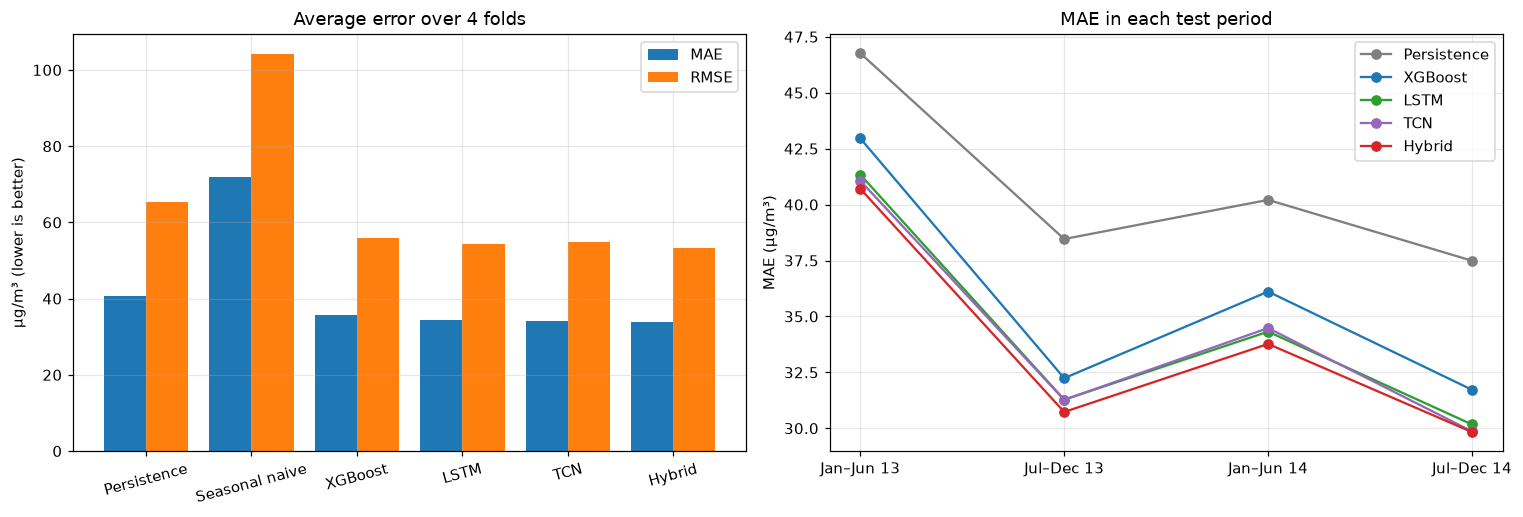

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

x = np.arange(len(MODELS))
axes[0].bar(x - 0.2, comparison["MAE"], width=0.4, label="MAE", color="tab:blue")
axes[0].bar(x + 0.2, comparison["RMSE"], width=0.4, label="RMSE", color="tab:orange")
axes[0].set_xticks(x, MODELS, rotation=15)
axes[0].set_ylabel("µg/m³ (lower is better)")
axes[0].set_title("Average error over 4 folds")
axes[0].legend()

for model in ["Persistence", "XGBoost", "LSTM", "TCN", "Hybrid"]:
    part = per_fold[per_fold["model"] == model]
    axes[1].plot(part["fold"], part["MAE"], marker="o", label=model, color=COLORS[model])
axes[1].set_xticks([1, 2, 3, 4], ["Jan–Jun 13", "Jul–Dec 13", "Jan–Jun 14", "Jul–Dec 14"])
axes[1].set_ylabel("MAE (µg/m³)")
axes[1].set_title("MAE in each test period")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{FIG}/17_all_models_comparison.png")
plt.show()

## 3. Forecast vs actual (last 7 days of the last fold)

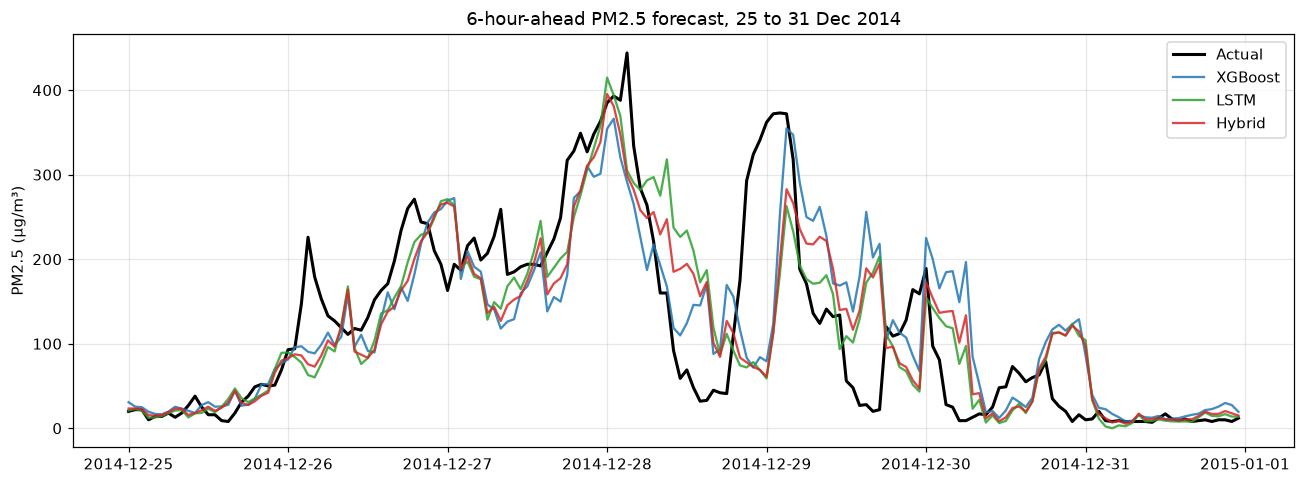

In [7]:
last_week = predictions.tail(7 * 24)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(last_week["forecast_for"], last_week["actual"], color="black", linewidth=2, label="Actual")
for model in ["XGBoost", "LSTM", "Hybrid"]:
    ax.plot(last_week["forecast_for"], last_week[model], label=model, color=COLORS[model], alpha=0.85)
ax.set_title("6-hour-ahead PM2.5 forecast, 25 to 31 Dec 2014")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/18_hybrid_forecast.png")
plt.show()

## 4. Where does the hybrid improve on XGBoost?

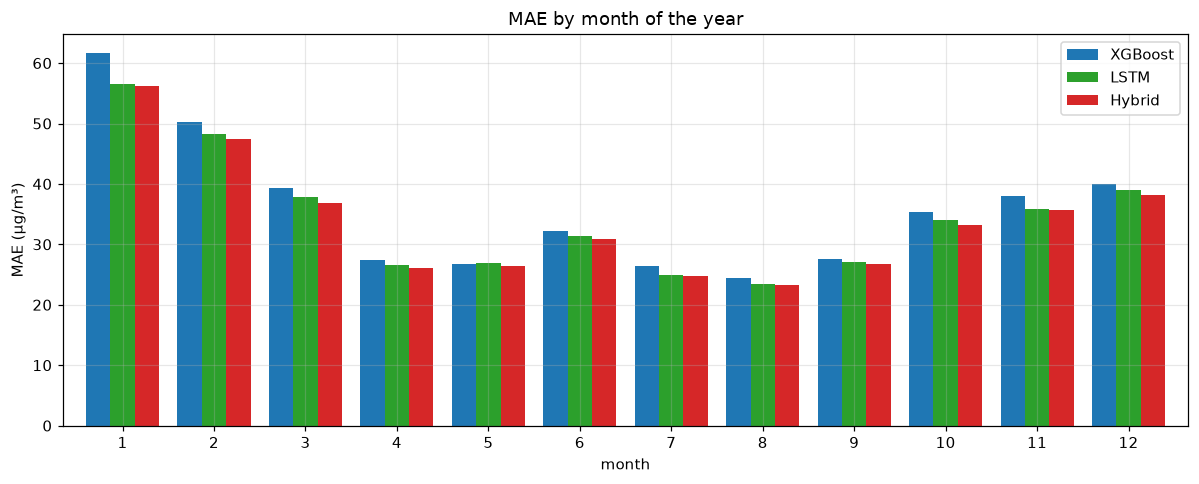

Months where the hybrid beats XGBoost: 12 of 12


month,1,2,3,4,5,6,7,8,9,10,11,12
XGBoost,61.7,50.2,39.3,27.4,26.8,32.2,26.5,24.4,27.6,35.4,38.0,40.0
LSTM,56.5,48.3,37.9,26.6,26.9,31.4,25.0,23.5,27.0,34.1,35.9,39.0
Hybrid,56.2,47.5,36.9,26.1,26.4,30.9,24.8,23.3,26.7,33.2,35.7,38.2


In [8]:
by_month = pd.DataFrame({
    model: (scored[model] - scored["actual"]).abs().groupby(scored["forecast_for"].dt.month).mean()
    for model in ["XGBoost", "LSTM", "Hybrid"]
}).round(1)
by_month.index.name = "month"

ax = by_month.plot(kind="bar", figsize=(11, 4.5), color=[COLORS[m] for m in by_month.columns], rot=0, width=0.8)
ax.set_title("MAE by month of the year")
ax.set_ylabel("MAE (µg/m³)")
plt.tight_layout()
plt.savefig(f"{FIG}/19_error_by_month.png")
plt.show()

print("Months where the hybrid beats XGBoost:", int((by_month["Hybrid"] < by_month["XGBoost"]).sum()), "of 12")
by_month.T

## Conclusion

In [9]:
best = comparison["MAE"].idxmin()
print(f"Best model by MAE: {best}")
for model in ["XGBoost", "LSTM", "TCN", "Hybrid"]:
    row = comparison.loc[model]
    print(f"  {model:8s} MAE {row['MAE']:.2f} | RMSE {row['RMSE']:.2f} | R2 {row['R2']:.3f} | "
          f"AQI exact {row['AQI category accuracy']:.1%} | AQI within one {row['AQI within one category']:.1%} | "
          f"vs persistence {row['MAE vs persistence']} | vs XGBoost {row['MAE vs XGBoost']}")
wins = (per_fold.pivot(index="fold", columns="model", values="MAE")[MODELS].idxmin(axis=1) == "Hybrid").sum()
print(f"Hybrid has the lowest MAE in {wins} of 4 folds")

Best model by MAE: Hybrid
  XGBoost  MAE 35.76 | RMSE 55.80 | R2 0.652 | AQI exact 53.9% | AQI within one 90.2% | vs persistence 12.2% | vs XGBoost 0.0%
  LSTM     MAE 34.28 | RMSE 54.38 | R2 0.667 | AQI exact 55.1% | AQI within one 90.2% | vs persistence 15.8% | vs XGBoost 4.1%
  TCN      MAE 34.17 | RMSE 54.82 | R2 0.662 | AQI exact 55.7% | AQI within one 90.4% | vs persistence 16.1% | vs XGBoost 4.4%
  Hybrid   MAE 33.76 | RMSE 53.41 | R2 0.680 | AQI exact 55.8% | AQI within one 90.6% | vs persistence 17.1% | vs XGBoost 5.6%
Hybrid has the lowest MAE in 4 of 4 folds


- Both sequence models beat XGBoost on MAE **without any hand-made lag features**, which confirms the gap identified in Phase 1.
- The **hybrid** of XGBoost, LSTM and temporal CNN is the most accurate model on every metric.
- All models are scored on the same measured hours of the same four future test periods, so the comparison is fair.